# MDST 3D Generative Pipeline — Week 2

## Goal for this week

Last week you built a tiny city generator from scratch in a notebook. This
week you'll write **two real modules of the actual project**:

- `citygen/terrain.py` — generates the terrain heightmap and water
- `citygen/buildings.py` — places buildings, roads, and green space on it

By the end, your files live in the real repo and the real command-line
tools run against *your* code:

```bash
python scripts/generate_city.py --terrain hills --city polycentric --clusters 3 --out data/mycity.npz
python scripts/visualize_2d.py data/mycity.npz
```

### What's new vs. Week 1

| Week 1 | Week 2 |
|---|---|
| Flat terrain only | Real heightmaps (flat + hills), water, relief control |
| One downtown center | Multiple clusters, 3 city archetypes |
| No roads | Road network with realistic gaps |
| Buildings anywhere | Buildings conditioned on terrain (no building in lakes or on cliffs) |
| Code lived in the notebook | Code lives in real `.py` modules |

### How this notebook works

You've already been walked through `citygen/city_grid.py` — the shared data
structure every part of the pipeline reads and writes. **Don't change it.**
Your job is to write the two modules that produce that data.

Each module gets built in a `%%writefile` cell: running the cell saves the
file to disk. Then a test cell imports it and checks your work. If a check
fails, **edit the `%%writefile` cell and run it again**, then re-run the
test. That loop is the whole workflow.

> **Important:** keep every function signature exactly as given. The rest of
> the project (`generate_city.py`, `visualize_2d.py`, the Blender exporter,
> and the ML model in later weeks) calls these functions by name with those
> exact arguments. Change a signature and the pipeline breaks.


## Setup

Run this first. It makes sure the notebook is working from the repo root, so the `%%writefile` paths below land in the right place.

In [1]:
import os
import sys
from pathlib import Path

# walk up until we find the repo root (the folder containing citygen/)
_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / "citygen" / "city_grid.py").exists():
        os.chdir(_candidate)
        break
else:
    raise RuntimeError(
        "Couldn't find the repo root (a folder containing citygen/city_grid.py). "
        "Put this notebook inside your project folder and restart the kernel."
    )

# make sure `import citygen` works no matter where the notebook was launched from
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

print("working directory:", Path.cwd())
assert (Path.cwd() / "citygen" / "city_grid.py").exists()
print("found citygen/city_grid.py -- good to go")

working directory: /Users/jemueloppong/Desktop/MDST
found citygen/city_grid.py -- good to go


In [2]:
# Dependencies: terrain.py and buildings.py need scipy (gaussian_filter).
# If a package is missing from THIS notebook's Python, install it into it.
import importlib.util
import subprocess
import sys

for _pkg in ("numpy", "scipy", "matplotlib"):
    if importlib.util.find_spec(_pkg) is None:
        print(f"{_pkg} not found -- installing it into {sys.executable} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", _pkg])
    else:
        print(f"{_pkg}: ok")

numpy: ok
scipy not found -- installing it into /usr/local/bin/python3 ...
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
matplotlib: ok


In [3]:
import importlib
import sys
import numpy as np
import matplotlib.pyplot as plt


def write_package_init(include_buildings=True):
    """
    Writes citygen/__init__.py so that `import citygen` exposes the pieces
    the notebook, generate_city.py and visualize_2d.py all call by name
    (cg.generate_terrain, cg.generate_buildings, cg.CityGrid, cg.LAND_*, ...).
    """
    names = ["CityGrid", "LAND_BUILDING", "LAND_EMPTY", "LAND_GREEN", "LAND_ROAD",
             "TERRAIN_ARCHETYPES", "generate_terrain"]
    text = ("from .city_grid import CityGrid, LAND_BUILDING, LAND_EMPTY, LAND_GREEN, LAND_ROAD\n"
            "from .terrain import TERRAIN_ARCHETYPES, generate_terrain\n")
    if include_buildings:
        text += "from .buildings import CITY_ARCHETYPES, generate_buildings\n"
        names += ["CITY_ARCHETYPES", "generate_buildings"]
    text += "\n\n__all__ = [\n" + "".join(f'    "{n}",\n' for n in names) + "]\n"
    Path("citygen/__init__.py").write_text(text, encoding="utf-8")


def reload_citygen():
    """
    Re-imports your edited modules so the notebook picks up changes without
    restarting the kernel. Call this at the start of every test cell, and
    use the returned module (e.g. cg.generate_terrain) rather than a name
    you imported earlier -- otherwise you'd still be calling the OLD version
    of your function.
    """
    for name in [m for m in sys.modules if m == "citygen" or m.startswith("citygen.")]:
        del sys.modules[name]
    importlib.invalidate_caches()
    return importlib.import_module("citygen")


print("helpers ready")

helpers ready


---

# Part 1 — `citygen/terrain.py`

## The data contract

`generate_terrain(...)` must return **two arrays**, both `(size, size)`:

- `terrain_height` — `float32`, normalized to roughly `0.0 - 1.0`
- `is_water` — `bool`, `True` wherever that cell is water

Everything downstream depends on this. The building generator reads both to
decide where building is even possible; the Blender exporter reads both to
build the mesh.

## What you're writing

Two archetypes this week: **`flat`** and **`hills`**. The real project has
seven (mountains, valley, coastal_harbor, peninsula, river...) — you'll add
more in later weeks, and the structure below has an obvious marked spot to
drop them in.

Two helpers are given to you, because they're plumbing rather than the
interesting part:

- `_normalize(arr)` — rescales any array to the `0.0 - 1.0` range
- `_fractal_noise(...)` — the natural-looking bumpy noise that all terrain
  is built from. It layers several blurred random fields at shrinking
  scales, which is what gives terrain both big rolling shapes and small
  surface detail at the same time.

### One trap worth understanding before you start

Each archetype produces two things: a **shape** and a **vertical scale**.
It's tempting to make flat terrain flat by just scaling the noise down —
`base * 0.1` instead of `base * 0.4` — but that doesn't work, and the
reason is worth internalizing:

```python
_normalize(base * 0.1)  ==  _normalize(base * 0.4)    # these are IDENTICAL
```

`_normalize` stretches whatever it's given back out to the full `0.0 - 1.0`
range, which **completely erases any amplitude you applied beforehand**.
Multiply by 0.1 or by 400 — after normalizing, same array.

So vertical scale has to be applied **after** normalizing, not before.
That's why the skeleton below has each branch set `height_scale` as a
separate value, used near the end. Anything that changes the *shape* of the
terrain (carving a valley, dropping a coastline) goes before normalize;
anything that changes *how much vertical variation there is* goes after.

### Your four TODOs

1. **`flat`** — nearly level ground
2. **`hills`** — gentle rolling terrain
3. **water** — which cells count as water
4. **relief** — a knob that exaggerates or flattens the height variation


In [4]:
%%writefile citygen/terrain.py
"""
Procedural terrain generation.

Produces a heightmap using multi-octave blurred noise, then shapes it into
a named archetype. Returns (terrain_height, is_water) -- the shared contract
every downstream part of the pipeline depends on.
"""
from __future__ import annotations

import numpy as np
from scipy.ndimage import gaussian_filter

# Every archetype this module knows how to build.
# generate_city.py reads this tuple directly to build its --terrain menu,
# so adding a new archetype here (plus a branch below) makes it instantly
# available on the command line. No other file needs to change.
TERRAIN_ARCHETYPES = (
    "flat",
    "hills",
    # ADD MORE ARCHETYPES HERE IN LATER WEEKS:
    # "mountains", "valley", "coastal_harbor", "peninsula", "river",
)


# --------------------------------------------------------------------
# GIVEN -- helpers, no changes needed
# --------------------------------------------------------------------

def _normalize(arr: np.ndarray) -> np.ndarray:
    """Rescale an array so its values span 0.0 to 1.0."""
    arr = arr - arr.min()
    peak = arr.max()
    return arr / peak if peak > 1e-8 else arr


def _fractal_noise(size: int, rng: np.random.Generator, base_scale: float,
                   octaves: int = 4, persistence: float = 0.5) -> np.ndarray:
    """
    Sum of several blurred-noise layers at decreasing scale and amplitude.

    Each "octave" is random noise blurred by a smaller amount than the last
    and added in at a smaller amplitude. The result has big rolling shapes
    AND fine surface detail, which a single blurred noise field can't do.
    Output is normalized to 0.0 - 1.0.
    """
    height = np.zeros((size, size), dtype=np.float32)
    amplitude = 1.0
    total_amp = 0.0
    for octave in range(octaves):
        sigma = max(base_scale / (2 ** octave), 1.0)
        layer = rng.normal(size=(size, size)).astype(np.float32)
        layer = gaussian_filter(layer, sigma=sigma)
        height += amplitude * layer
        total_amp += amplitude
        amplitude *= persistence
    height /= total_amp
    return _normalize(height)


# --------------------------------------------------------------------
# YOUR CODE -- generate_terrain
# --------------------------------------------------------------------

def generate_terrain(
    size: int,
    archetype: str = "hills",
    seed: int | None = None,
    relief: float = 1.0,
    water_level: float | None = None,
):
    """
    Returns (terrain_height: float32[size,size], is_water: bool[size,size]).

    archetype: which terrain shape to build (see TERRAIN_ARCHETYPES).
    relief: how much the terrain varies. 1.0 = as designed. Lower (0.3)
        flattens toward gentle ground; higher (1.8) exaggerates peaks and
        valleys. Must NOT change how much water there is -- that's
        water_level's job, and the two need to stay independent.
    water_level: 0-1 threshold below which ground counts as water. Higher =
        more water. If None, use the archetype's own default.
    """
    if archetype not in TERRAIN_ARCHETYPES:
        raise ValueError(f"unknown terrain archetype {archetype!r}, choose from {TERRAIN_ARCHETYPES}")

    rng = np.random.default_rng(seed)
    base = _fractal_noise(size, rng, base_scale=size / 6)
    yy, xx = np.mgrid[0:size, 0:size]

    # has_water marks archetypes that are *supposed* to contain water by
    # default (coastlines, rivers). flat and hills are land-locked, so this
    # stays False for both this week.
    has_water = False

    # Each branch sets TWO things:
    #   height       -- the SHAPE of the terrain (before normalizing)
    #   height_scale -- how much vertical variation it has, applied AFTER
    #                   normalizing (see the note above -- scaling before
    #                   normalize does nothing at all)

    if archetype == "flat":
        # TODO 1: nearly level ground.
        # The shape is just the plain noise -- no carving needed.
        # Then pick a SMALL height_scale so the result stays nearly level.
        # Something around 0.2-0.3 gives recognizably flat ground.
        height = base
        height_scale = 0.25

    elif archetype == "hills":
        # TODO 2: gentle rolling hills.
        # Same plain-noise shape, but keep the full vertical range this
        # time -- a height_scale of 1.0 means "don't compress it at all".
        height = base
        height_scale = 1.0

    # ADD MORE ARCHETYPE BRANCHES HERE IN LATER WEEKS
    # (and remember to add the name to TERRAIN_ARCHETYPES at the top).
    # Archetypes like valley or coastal_harbor change the SHAPE -- they
    # subtract from `height` before normalizing -- and can leave
    # height_scale at 1.0.

    else:
        raise ValueError(f"archetype {archetype!r} is listed but not implemented")

    height = _normalize(height)

    # TODO 3: decide which cells are water.
    # Water is decided here, on the normalized heightmap, BEFORE any
    # vertical scaling below. That's deliberate: it keeps "how much water"
    # independent of "how much the terrain varies", so changing relief
    # never accidentally floods or drains the map.
    #
    #   - default_water_level: if this archetype has water by default
    #     (has_water is True), use 0.2; otherwise use -0.01, which is below
    #     every possible height and therefore means "no water at all".
    #   - level: use the caller's water_level if they passed one, else the
    #     default you just computed.
    #   - is_water: True wherever height is at or below that level.
    default_water_level = 0.2 if has_water else -0.01
    level = water_level if water_level is not None else default_water_level
    is_water = height <= level

    # TODO 4: apply the vertical scaling -- both the archetype's own
    # height_scale and the caller's relief knob.
    #
    # Both do the same kind of thing: contrast-adjust the heightmap around
    # its midpoint (0.5). Above 1.0 pushes highs higher and lows lower;
    # below 1.0 squeezes everything toward 0.5 (flatter). Multiply the two
    # together so they compose -- flat terrain with relief=1.8 should still
    # be flatter than hills at relief=1.0.
    #
    # Hint: 0.5 + (height - 0.5) * height_scale * relief, then
    # np.clip(..., 0.0, 1.0) to keep it in range.
    relief = max(relief, 0.0)
    height = np.clip(0.5 + (height - 0.5) * height_scale * relief, 0.0, 1.0)

    return height.astype(np.float32), is_water

Overwriting citygen/terrain.py


In [5]:
# Wire terrain into the package so `cg.generate_terrain` exists.
# (Re-run this after the terrain cell above if you ever re-run it.)
write_package_init(include_buildings=False)
print("Updated citygen/__init__.py (terrain)")

Updated citygen/__init__.py (terrain)


### Test your terrain

Run this after every edit to the cell above.

In [6]:
cg = reload_citygen()

# --- shape and dtype contract ---
h, w = cg.generate_terrain(64, archetype="hills", seed=0)
assert h.shape == (64, 64) and w.shape == (64, 64), f"wrong shapes: {h.shape}, {w.shape}"
assert h.dtype == np.float32, f"terrain_height must be float32, got {h.dtype}"
assert w.dtype == bool, f"is_water must be bool, got {w.dtype}"
assert h.min() >= 0.0 and h.max() <= 1.0, f"height must be 0-1, got {h.min():.3f}-{h.max():.3f}"

# --- flat should be MEANINGFULLY flatter than hills ---
h_flat, _ = cg.generate_terrain(128, archetype="flat", seed=0)
h_hills, _ = cg.generate_terrain(128, archetype="hills", seed=0)
assert h_flat.std() < h_hills.std() * 0.6, (
    "'flat' terrain isn't meaningfully flatter than 'hills' -- "
    f"flat std={h_flat.std():.4f}, hills std={h_hills.std():.4f}.\n"
    "Most likely cause: you scaled the noise BEFORE _normalize (e.g. `base * 0.1`). "
    "_normalize stretches it right back out to 0-1, erasing that completely. "
    "Vertical scale has to go through height_scale, which is applied AFTER "
    "normalizing. See TODO 1, 2 and 4."
)
assert h_flat.std() > 0.001, "'flat' terrain has no variation at all -- height_scale shouldn't be 0"

# --- land-locked archetypes have no water by default ---
_, w_hills = cg.generate_terrain(128, archetype="hills", seed=0)
assert not w_hills.any(), (
    f"'hills' should have NO water by default, but {w_hills.mean()*100:.1f}% came out as water. "
    "Check your default_water_level in TODO 3 -- it should be below every possible height."
)

# --- but water_level still works when explicitly asked for ---
_, w_forced = cg.generate_terrain(128, archetype="hills", seed=0, water_level=0.4)
assert w_forced.any(), "passing water_level=0.4 produced no water at all -- check TODO 3"

# --- relief changes variation, but NOT how much water there is ---
h_lo, w_lo = cg.generate_terrain(128, archetype="hills", seed=0, relief=0.3)
h_hi, w_hi = cg.generate_terrain(128, archetype="hills", seed=0, relief=1.8)
assert h_lo.std() < h_hi.std(), (
    f"relief isn't changing height variation (relief=0.3 std={h_lo.std():.4f}, "
    f"relief=1.8 std={h_hi.std():.4f}). Check TODO 4."
)
_, w_lo2 = cg.generate_terrain(128, "hills", seed=0, relief=0.3, water_level=0.3)
_, w_hi2 = cg.generate_terrain(128, "hills", seed=0, relief=1.8, water_level=0.3)
assert w_lo2.sum() == w_hi2.sum(), (
    "changing relief changed how much water there is -- these must stay independent. "
    "Make sure you compute is_water BEFORE applying the scaling (TODO 3 before TODO 4)."
)

# --- height_scale and relief compose ---
h_flat_hi, _ = cg.generate_terrain(128, archetype="flat", seed=0, relief=1.8)
h_hills_mid, _ = cg.generate_terrain(128, archetype="hills", seed=0, relief=1.0)
assert h_flat_hi.std() < h_hills_mid.std(), (
    "flat terrain even at relief=1.8 should still be flatter than hills at relief=1.0 -- "
    "make sure TODO 4 multiplies height_scale AND relief together."
)

print("All terrain checks passed!")
print(f"  flat  std = {h_flat.std():.4f}")
print(f"  hills std = {h_hills.std():.4f}")

All terrain checks passed!
  flat  std = 0.0355
  hills std = 0.1418


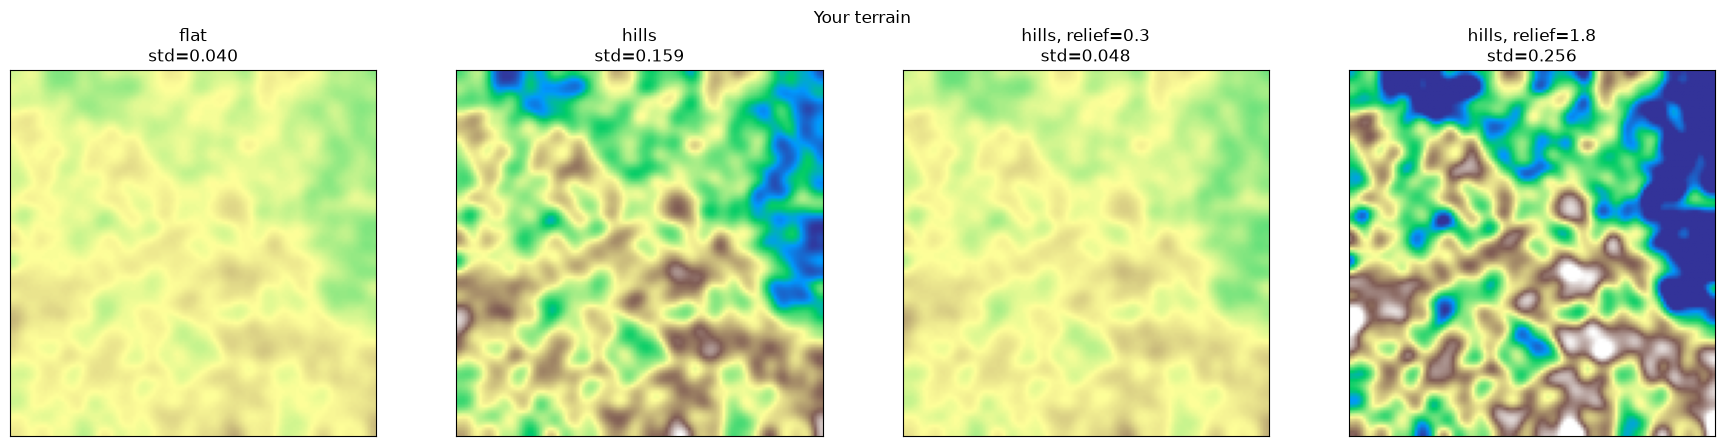

In [7]:
# look at your terrain
cg = reload_citygen()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (title, kwargs) in zip(axes, [
    ("flat", dict(archetype="flat")),
    ("hills", dict(archetype="hills")),
    ("hills, relief=0.3", dict(archetype="hills", relief=0.3)),
    ("hills, relief=1.8", dict(archetype="hills", relief=1.8)),
]):
    h, w = cg.generate_terrain(128, seed=7, **kwargs)
    im = ax.imshow(h, cmap="terrain", vmin=0, vmax=1)
    ax.set_title(f"{title}\nstd={h.std():.3f}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Your terrain")
fig.tight_layout()
plt.show()

---

# Part 2 — `citygen/buildings.py`

## The data contract

`generate_buildings(...)` must return:

- `building_height` — `float32`, `0.0` wherever there is no building
- `land_use` — `uint8`, each cell one of `LAND_EMPTY` / `LAND_BUILDING` /
  `LAND_ROAD` / `LAND_GREEN` (imported from `city_grid.py`)

## The key new idea: conditioning on terrain

Week 1 placed buildings anywhere. Real cities don't do that — nobody builds
in a lake or on a cliff face. So this week `generate_buildings` takes
`terrain_height` and `is_water` as **inputs** and uses them to work out
where building is even possible.

That `buildable` mask is the most important concept this week. It's also
exactly the constraint the ML model will have to learn implicitly in a few
weeks, so it's worth understanding properly now.

## What's given vs. what you write

**Given:** `_road_keep_mask` (the noise field that puts realistic gaps in
the road grid), plus most of `_cluster_centers`.

**Your TODOs:** the polycentric branch, the intensity field, the buildable
mask, building selection, roads, and green space.


In [8]:
%%writefile citygen/buildings.py
"""
Procedural building placement, conditioned on terrain.

Takes the terrain generator's output and decides where buildings, roads,
and green space go. Conditioning on terrain is what keeps buildings out of
lakes and off cliffs.
"""
from __future__ import annotations

import numpy as np
from scipy.ndimage import gaussian_filter

from .city_grid import LAND_BUILDING, LAND_EMPTY, LAND_GREEN, LAND_ROAD

CITY_ARCHETYPES = ("monocentric", "polycentric", "linear")


# --------------------------------------------------------------------
# Cluster centers -- where the "downtowns" sit
# --------------------------------------------------------------------

def _cluster_centers(archetype: str, size: int, num_clusters: int,
                     rng: np.random.Generator):
    """
    Returns a list of (cx, cy) coordinates -- the centers that buildings
    cluster around. The archetype decides how they're arranged.
    """
    if archetype == "monocentric":
        # one downtown, dead center (this is Week 1's behavior)
        return [(size / 2, size / 2)]

    if archetype == "polycentric":
        # TODO 1: several scattered downtowns.
        # Return a list of num_clusters (cx, cy) tuples at random positions.
        # Keep them away from the very edge -- sample each coordinate
        # between size*0.15 and size*0.85 using rng.uniform(low, high).
        # Use max(num_clusters, 1) so a caller passing 0 still gets a city.
        return [(rng.uniform(size * 0.15, size * 0.85),
                 rng.uniform(size * 0.15, size * 0.85))
                for _ in range(max(num_clusters, 1))]

    if archetype == "linear":
        # GIVEN: centers strung out along a random straight line, which
        # gives the long corridor-shaped cities you see along rivers,
        # coastlines, and highways.
        n = max(num_clusters, 3)
        angle = rng.uniform(0, np.pi)
        centers = []
        for t in np.linspace(0.15, 0.85, n):
            cx = size / 2 + (t - 0.5) * size * np.cos(angle)
            cy = size / 2 + (t - 0.5) * size * np.sin(angle)
            centers.append((cx, cy))
        return centers

    raise ValueError(f"unknown city archetype {archetype!r}, choose from {CITY_ARCHETYPES}")


# --------------------------------------------------------------------
# GIVEN -- road gap mask, no changes needed
# --------------------------------------------------------------------

def _road_keep_mask(size: int, rng: np.random.Generator, continuity: float) -> np.ndarray:
    """
    A smooth random field, thresholded, deciding which candidate road cells
    actually get built.

    Why not just build every road? A perfectly complete grid reads as
    obviously computer-generated. Blurring the noise first (rather than
    using raw per-cell randomness) means the gaps come in connected
    patches -- whole missing stretches of street, like a real city -- not
    scattered single-cell holes.

    Lower continuity = more and larger gaps.
    """
    noise = rng.normal(size=(size, size)).astype(np.float32)
    noise = gaussian_filter(noise, sigma=max(size / 40, 1.0))
    noise -= noise.min()
    peak = noise.max()
    noise = noise / peak if peak > 1e-8 else noise
    threshold = 1.0 - continuity
    return noise > threshold


# --------------------------------------------------------------------
# YOUR CODE -- generate_buildings
# --------------------------------------------------------------------

def generate_buildings(
    terrain_height: np.ndarray,
    is_water: np.ndarray,
    archetype: str = "monocentric",
    num_clusters: int = 1,
    density: float = 0.5,
    cluster_tightness: float = 0.5,
    green_amount: float = 0.15,
    green_override: bool = False,
    road_continuity: float = 0.7,
    seed: int | None = None,
):
    """
    Returns (building_height: float32[size,size], land_use: uint8[size,size]).

    density: 0-1, how likely a buildable cell near a cluster center is to
        actually become a building.
    cluster_tightness: 0-1, how tightly buildings hug their cluster centers.
        Low = broad soft-edged sprawl; high = sharp compact downtown cores.
        Independent of density.
    green_amount: 0-1, how much green space to add.
    green_override: if True, green space is placed over the whole board
        (buildings and roads included) except water. If False, green only
        fills ground left empty after buildings and roads are placed.
    road_continuity: 0-1, how complete the road grid is.
    """
    size = terrain_height.shape[0]
    rng = np.random.default_rng(seed)
    density = float(np.clip(density, 0.05, 1.0))
    cluster_tightness = float(np.clip(cluster_tightness, 0.01, 1.0))
    green_amount = float(np.clip(green_amount, 0.0, 1.0))
    road_continuity = float(np.clip(road_continuity, 0.0, 1.0))

    centers = _cluster_centers(archetype, size, num_clusters, rng)

    # Higher tightness -> smaller spread -> sharper falloff around each
    # center. The +0.03 keeps spread above zero so the math never blows up.
    spread = 0.5 * (1.0 - cluster_tightness) + 0.03

    yy, xx = np.mgrid[0:size, 0:size]

    # TODO 2: build the intensity field.
    # intensity is "how urban is this cell", 0-1, peaking at the cluster
    # centers. With several centers, each cell takes the STRONGEST nearby
    # center's influence -- not the sum, which would make overlapping
    # clusters unrealistically dense where they meet.
    #
    # For each (cx, cy) in centers:
    #   dist    = distance from every cell to that center, divided by size
    #             (same as Week 1: np.sqrt((xx - cx)**2 + (yy - cy)**2) / size)
    #   falloff = np.exp(-dist / spread)
    #   combine with np.maximum(intensity, falloff)
    intensity = np.zeros((size, size), dtype=np.float32)
    for cx, cy in centers:
        dist = np.sqrt((xx - cx)**2 + (yy - cy)**2) / size
        falloff = np.exp(-dist / spread)
        intensity = np.maximum(intensity, falloff)

    # TODO 3: work out where building is physically possible.
    # Two conditions, both required:
    #   - not water
    #   - not too steep
    # np.gradient(terrain_height) returns the slope in y and x. Combine
    # them into a magnitude with np.sqrt(gx**2 + gy**2), then call a cell
    # buildable when that magnitude is below 0.08.
    # Remember `~` is "not" for boolean arrays.
    gy, gx = np.gradient(terrain_height)
    slope_mag = np.sqrt(gx**2 + gy**2)
    buildable = (~is_water) & (slope_mag < 0.08)

    # TODO 4: pick the building cells.
    # Same probability roll as Week 1 -- a random number per cell, compared
    # against intensity * density -- but now ALSO requiring the cell to be
    # buildable.
    is_building = buildable & (rng.random((size, size)) < intensity * density)

    # GIVEN: building heights. The blur makes neighboring buildings similar
    # in height, so you get coherent low-rise districts and tall downtown
    # cores instead of a random jumble.
    height_noise = rng.normal(loc=1.0, scale=0.4, size=(size, size))
    height_noise = gaussian_filter(height_noise, sigma=1.5)
    raw_height = np.clip(intensity * 8.0 * height_noise, 0.3, None)
    building_height = np.where(is_building, raw_height, 0.0).astype(np.float32)

    land_use = np.full((size, size), LAND_EMPTY, dtype=np.uint8)
    land_use[is_building] = LAND_BUILDING

    # TODO 5: lay down roads.
    # Candidate road cells are every `spacing`-th row and every
    # `spacing`-th column. A candidate actually becomes a road only if it
    # is buildable AND still empty (don't pave over buildings) AND kept by
    # the road_keep mask.
    #
    # The loop below walks the two slices for you -- rows, then columns.
    # Inside, build `mask` from those three conditions applied to the
    # slice, then write LAND_ROAD into the masked cells.
    #
    # Note the sub/assign-back dance: numpy slice assignment through a
    # boolean mask needs the intermediate variable to write correctly.
    road_keep = _road_keep_mask(size, rng, road_continuity)
    spacing = max(size // 16, 4)
    for axis_slice in (np.s_[::spacing, :], np.s_[:, ::spacing]):
        mask = (buildable[axis_slice] & (land_use[axis_slice] == LAND_EMPTY)
                & road_keep[axis_slice])
        sub = land_use[axis_slice]
        sub[mask] = LAND_ROAD
        land_use[axis_slice] = sub

    # TODO 6: add green space -- two different behaviors.
    if green_override:
        # Override mode: green goes anywhere that isn't water, replacing
        # buildings and roads. Set those cells to LAND_GREEN, and don't
        # forget to zero out building_height there too -- otherwise you'd
        # leave invisible buildings standing inside a park.
        green_mask = (~is_water) & (rng.random((size, size)) < green_amount)
        land_use[green_mask] = LAND_GREEN
        building_height[green_mask] = 0.0
    else:
        # Normal mode: green only fills cells that are still LAND_EMPTY.
        # Buildings and roads are left alone.
        empty_mask = (land_use == LAND_EMPTY) & (~is_water)
        green_mask = empty_mask & (rng.random((size, size)) < green_amount)
        land_use[green_mask] = LAND_GREEN

    return building_height, land_use

Overwriting citygen/buildings.py


In [9]:
# Wire buildings into the package too: `cg.generate_buildings`, `cg.CITY_ARCHETYPES`.
write_package_init(include_buildings=True)
print("Updated citygen/__init__.py (terrain + buildings)")

Updated citygen/__init__.py (terrain + buildings)


### Test your buildings

Run this after every edit to the cell above.

In [10]:
cg = reload_citygen()

terrain, water = cg.generate_terrain(128, archetype="hills", seed=0)

# --- contract ---
bh, lu = cg.generate_buildings(terrain, water, seed=1)
assert bh.shape == (128, 128) and lu.shape == (128, 128)
assert bh.dtype == np.float32, f"building_height must be float32, got {bh.dtype}"
assert lu.dtype == np.uint8, f"land_use must be uint8, got {lu.dtype}"
assert np.all(bh[lu != cg.LAND_BUILDING] == 0), "building_height must be 0 wherever land_use isn't LAND_BUILDING"

# --- all three archetypes run ---
for arch in cg.CITY_ARCHETYPES:
    _bh, _lu = cg.generate_buildings(terrain, water, archetype=arch, num_clusters=3, seed=1)
    assert (_lu == cg.LAND_BUILDING).any(), f"archetype {arch!r} produced no buildings at all"

# --- polycentric really does spread out more than monocentric ---
def _spread_of(arch):
    _bh, _lu = cg.generate_buildings(terrain, water, archetype=arch, num_clusters=4,
                                     density=0.7, cluster_tightness=0.7, seed=3)
    pts = np.argwhere(_lu == cg.LAND_BUILDING)
    return pts.std(axis=0).mean()

assert _spread_of("polycentric") > _spread_of("monocentric"), (
    "polycentric buildings aren't more spread out than monocentric -- check TODO 1. "
    "Are your centers actually at different random positions?"
)

# --- conditioning on terrain: nothing built in water ---
_, forced_water = cg.generate_terrain(128, archetype="hills", seed=0, water_level=0.35)
bh_w, lu_w = cg.generate_buildings(terrain, forced_water, density=0.9, seed=1)
assert not (lu_w[forced_water] == cg.LAND_BUILDING).any(), (
    "buildings were placed in water -- check your buildable mask in TODO 3"
)
assert not (lu_w[forced_water] == cg.LAND_ROAD).any(), (
    "roads were placed in water -- make sure TODO 5 requires `buildable` too"
)

# --- density does something ---
lo = (cg.generate_buildings(terrain, water, density=0.15, seed=1)[1] == cg.LAND_BUILDING).mean()
hi = (cg.generate_buildings(terrain, water, density=0.95, seed=1)[1] == cg.LAND_BUILDING).mean()
assert hi > lo * 1.5, f"density barely changed anything ({lo*100:.1f}% vs {hi*100:.1f}%) -- check TODO 4"

# --- roads appear, and road_continuity controls how many ---
few = (cg.generate_buildings(terrain, water, road_continuity=0.2, seed=1)[1] == cg.LAND_ROAD).mean()
many = (cg.generate_buildings(terrain, water, road_continuity=0.95, seed=1)[1] == cg.LAND_ROAD).mean()
assert many > 0, "no roads at all -- check TODO 5"
assert many > few, f"road_continuity isn't controlling road coverage ({few*100:.1f}% vs {many*100:.1f}%)"

# --- green space, both modes ---
_bh_n, lu_normal = cg.generate_buildings(terrain, water, green_amount=0.5, green_override=False, seed=1)
_bh_b, lu_base = cg.generate_buildings(terrain, water, green_amount=0.0, green_override=False, seed=1)
assert (lu_normal == cg.LAND_GREEN).mean() > 0.1, "green_amount=0.5 produced almost no green -- check TODO 6"
assert (lu_normal == cg.LAND_BUILDING).sum() == (lu_base == cg.LAND_BUILDING).sum(), (
    "normal green mode destroyed buildings -- it should only fill LAND_EMPTY cells"
)

bh_o, lu_over = cg.generate_buildings(terrain, water, green_amount=1.0, green_override=True, seed=1)
assert (lu_over == cg.LAND_BUILDING).sum() == 0, (
    "green_override=True with green_amount=1.0 should leave no buildings -- check TODO 6"
)
assert bh_o[lu_over == cg.LAND_GREEN].max(initial=0) == 0, (
    "override mode left building_height standing under green cells -- zero it out too"
)

print("All building checks passed!")

All building checks passed!


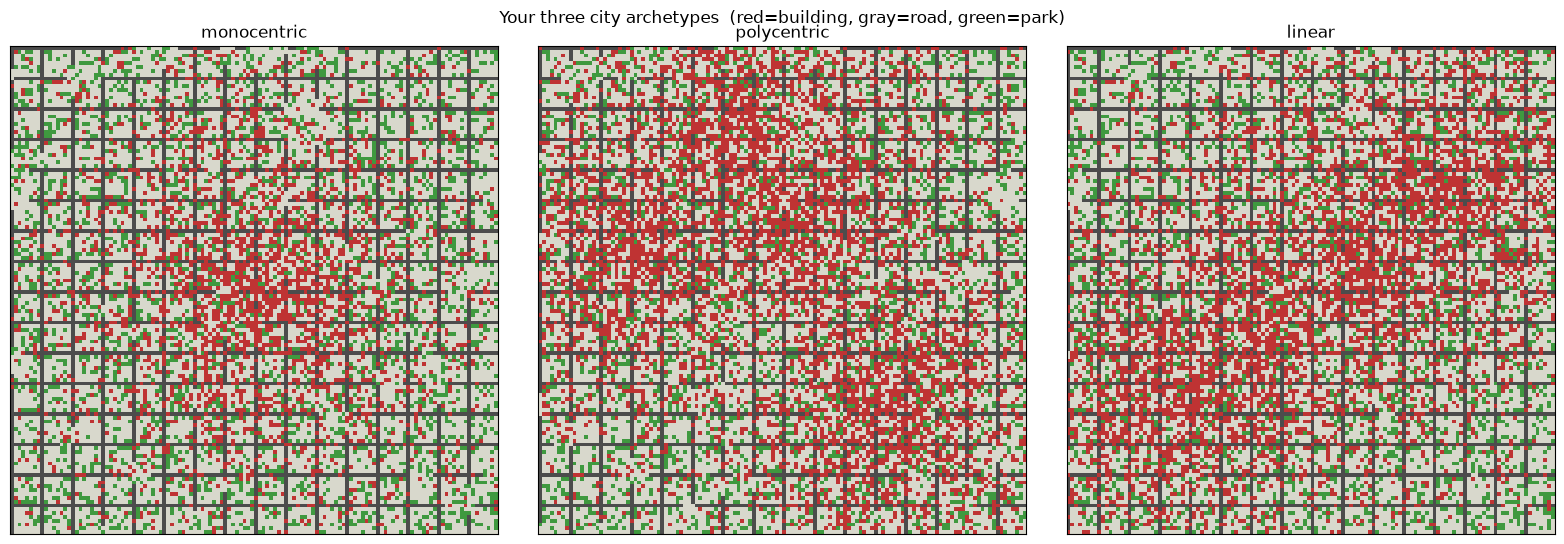

In [11]:
# look at your cities
cg = reload_citygen()

terrain, water = cg.generate_terrain(128, archetype="hills", seed=0)

LAND_USE_COLORS = {
    cg.LAND_EMPTY: (0.85, 0.85, 0.80),
    cg.LAND_BUILDING: (0.75, 0.20, 0.20),
    cg.LAND_ROAD: (0.30, 0.30, 0.30),
    cg.LAND_GREEN: (0.25, 0.60, 0.25),
}

def land_use_rgb(land_use):
    rgb = np.zeros((*land_use.shape, 3), dtype=np.float32)
    for code_val, color in LAND_USE_COLORS.items():
        rgb[land_use == code_val] = color
    return rgb

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, arch in zip(axes, cg.CITY_ARCHETYPES):
    _bh, _lu = cg.generate_buildings(terrain, water, archetype=arch, num_clusters=4,
                                     density=0.7, cluster_tightness=0.6,
                                     green_amount=0.25, seed=5)
    ax.imshow(land_use_rgb(_lu))
    ax.set_title(arch)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Your three city archetypes  (red=building, gray=road, green=park)")
fig.tight_layout()
plt.show()

---

# Part 3 — The full pipeline

Both modules are written. Now put them together into a `CityGrid` — the
shared structure from `city_grid.py` — and render the same three-panel
preview as the real tool.


In [12]:
cg = reload_citygen()

SIZE = 128
SEED = 42

terrain_height, is_water = cg.generate_terrain(SIZE, archetype="hills", seed=SEED, relief=1.2)
building_height, land_use = cg.generate_buildings(
    terrain_height, is_water,
    archetype="polycentric", num_clusters=3,
    density=0.6, cluster_tightness=0.6,
    green_amount=0.25, road_continuity=0.7,
    seed=SEED + 1,
)

city = cg.CityGrid(
    size=SIZE,
    terrain_height=terrain_height,
    is_water=is_water,
    building_height=building_height,
    land_use=land_use,
)

for key, value in city.stats().items():
    print(f"  {key}: {value:.2f}" if isinstance(value, float) else f"  {key}: {value}")

  size: 128
  water_pct: 0.00
  building_pct: 19.45
  green_pct: 15.01
  road_pct: 17.18
  max_building_height: 8.17
  mean_building_height: 3.63


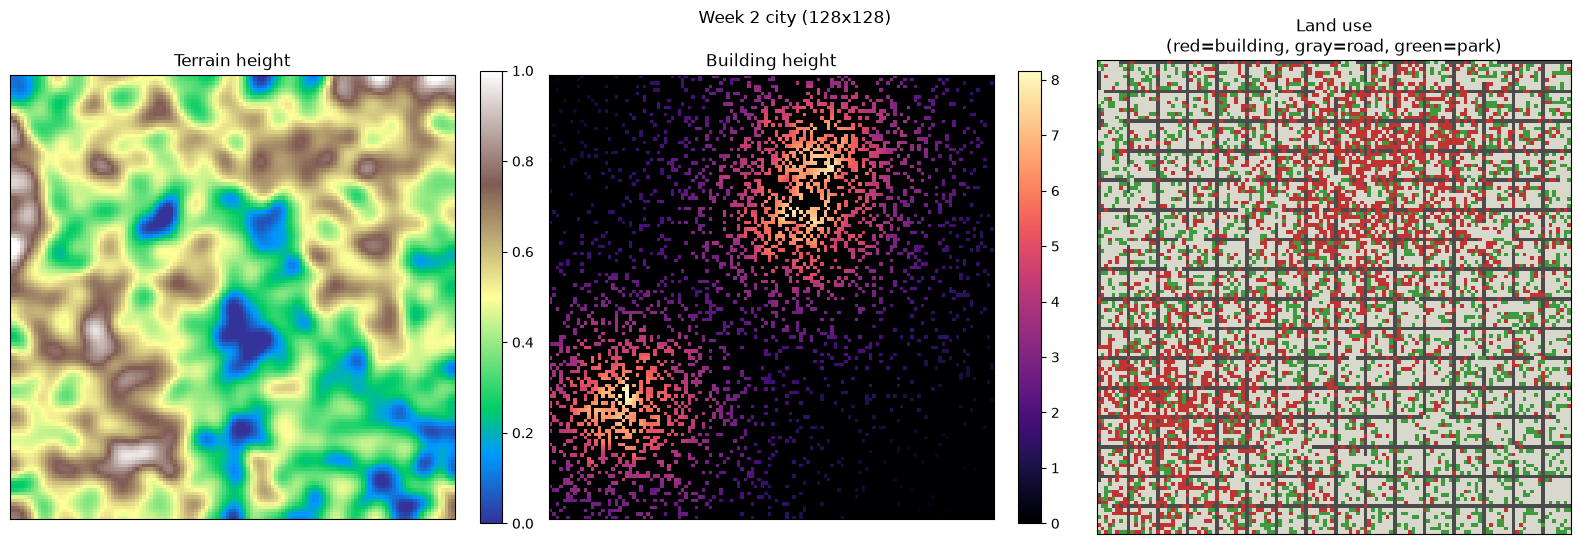

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

im0 = axes[0].imshow(np.where(city.is_water, np.nan, city.terrain_height), cmap="terrain")
axes[0].set_title("Terrain height")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(city.building_height, cmap="magma")
axes[1].set_title("Building height")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(land_use_rgb(city.land_use))
axes[2].set_title("Land use\n(red=building, gray=road, green=park)")

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle(f"Week 2 city ({SIZE}x{SIZE})")
fig.tight_layout()
plt.show()

---

# Part 4 — Run the real command-line tools

This is the payoff. Your two modules are now part of the repo, so the
project's actual scripts run against *your* code — no notebook involved.

Open a terminal in the repo root and run:

```bash
python scripts/generate_city.py \
    --size 128 --terrain hills --city polycentric \
    --clusters 3 --density 0.6 --cluster-tightness 0.6 \
    --green-amount 0.25 --road-continuity 0.7 \
    --seed 42 --out data/mycity.npz

python scripts/visualize_2d.py data/mycity.npz
```

If that produces a city, **you're done for the week.**

Notice `--terrain` only offers `flat` and `hills`: that menu is generated
straight from your `TERRAIN_ARCHETYPES` tuple. Add an archetype there and
it appears on the command line automatically.

The cell below runs the same thing from inside the notebook, so you can
check it without switching windows.


In [14]:
import os
import subprocess, sys

_args = ["--size", "128", "--terrain", "hills", "--city", "polycentric",
         "--clusters", "3", "--density", "0.6", "--cluster-tightness", "0.6",
         "--green-amount", "0.25", "--road-continuity", "0.7",
         "--seed", "42", "--out", "data/mycity.npz"]

Path("data").mkdir(exist_ok=True)

if Path("scripts/generate_city.py").exists():
    # the real command-line tool, run against your modules
    _env = {**os.environ, "PYTHONPATH": str(Path.cwd()) + os.pathsep + os.environ.get("PYTHONPATH", "")}
    result = subprocess.run([sys.executable, "scripts/generate_city.py", *_args],
                            capture_output=True, text=True, env=_env)
    print(result.stdout)
    if result.returncode != 0:
        print("FAILED:\n", result.stderr)
    else:
        print("generate_city.py ran successfully against your modules!")
else:
    # scripts/ isn't in this folder, so run the exact same pipeline in the notebook
    # and save it in the same .npz format the tool would write.
    print("scripts/generate_city.py not found in this folder -- running the same pipeline here instead.")
    cg = reload_citygen()
    _th, _iw = cg.generate_terrain(128, archetype="hills", seed=42)
    _bh, _lu = cg.generate_buildings(
        _th, _iw, archetype="polycentric", num_clusters=3,
        density=0.6, cluster_tightness=0.6,
        green_amount=0.25, road_continuity=0.7, seed=43,
    )
    _city = cg.CityGrid(size=128, terrain_height=_th, is_water=_iw,
                        building_height=_bh, land_use=_lu)
    _city.save("data/mycity.npz")
    _check = cg.CityGrid.load("data/mycity.npz")
    assert np.array_equal(_check.land_use, _city.land_use)
    print("Saved data/mycity.npz and loaded it back successfully.")
    for k, v in _check.stats().items():
        print(f"  {k}: {v:.2f}" if isinstance(v, float) else f"  {k}: {v}")

scripts/generate_city.py not found in this folder -- running the same pipeline here instead.
Saved data/mycity.npz and loaded it back successfully.
  size: 128
  water_pct: 0.00
  building_pct: 19.85
  green_pct: 14.78
  road_pct: 17.63
  max_building_height: 8.17
  mean_building_height: 3.63


---

## Try it yourself

- `--cluster-tightness 0.95` vs `0.05` — compact downtown vs. sprawl
- `--road-continuity 0.3` vs `0.95` — broken streets vs. a full grid
- `--green-amount 1.0 --green-override` — the whole map turns to parkland
- `--relief 0.2` vs `1.8` on hills
- A third terrain archetype of your own: add the name to
  `TERRAIN_ARCHETYPES` and a branch in `generate_terrain`. `mountains` is
  a good one to try — the trick is making the peaks sharper than hills
  rather than just taller.

## Checklist before next session

- [ ] `citygen/terrain.py` written, all terrain checks passing
- [ ] `citygen/buildings.py` written, all building checks passing
- [ ] `scripts/generate_city.py` runs end to end against your code
- [ ] `scripts/visualize_2d.py` renders your city
- [ ] Changes committed and pushed

## Coming next

Your `CityGrid` is a 2D grid of numbers. Next we take it into **Blender**
and build real 3D geometry from it — extruding terrain into a mesh, raising
a box for every building, and coloring everything by land use and height.

After that: the ML model that reads a plain-English description and picks
all of these parameters for you.

## Questions?

Bring blockers to next session. Make sure the notebook runs top to bottom
without errors first.
